In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [2]:
df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

df = df.drop(
    columns=["nameOrig", "nameDest", "isFlaggedFraud"]
)

df["errorBalanceOrig"] = (
    df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
)

df["errorBalanceDest"] = (
    df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
)

df = pd.get_dummies(
    df,
    columns=["type"],
    dtype=int
)

X = df.drop(columns=["isFraud"])
y = df["isFraud"]

train_end = df["step"].quantile(0.70)
validation_end = df["step"].quantile(0.85)

train_mask = df["step"] <= train_end

validation_mask = (
    (df["step"] > train_end) &
    (df["step"] <= validation_end)
)

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

In [3]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

print(X_train_sample.shape)
print(y_train_sample.value_counts())

(500000, 13)
isFraud
0    499592
1       408
Name: count, dtype: int64


In [4]:
dt_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

In [5]:
print("Training Decision Tree...")

dt_model.fit(
    X_train_sample,
    y_train_sample
)

print("Decision Tree training completed!")

Training Decision Tree...
Decision Tree training completed!


In [6]:
dt_predictions = dt_model.predict(X_val)

dt_probabilities = dt_model.predict_proba(X_val)[:, 1]

In [7]:
dt_precision = precision_score(y_val, dt_predictions)

dt_recall = recall_score(y_val, dt_predictions)

dt_f1 = f1_score(y_val, dt_predictions)

dt_roc_auc = roc_auc_score(y_val, dt_probabilities)

dt_pr_auc = average_precision_score(y_val, dt_probabilities)

print("FRAUDSHIELD AI - DECISION TREE")

print("--------------------------------")

print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)
print("ROC-AUC:", dt_roc_auc)
print("PR-AUC:", dt_pr_auc)

FRAUDSHIELD AI - DECISION TREE
--------------------------------
Precision: 0.9447236180904522
Recall: 1.0
F1 Score: 0.9715762273901809
ROC-AUC: 1.0
PR-AUC: 1.0


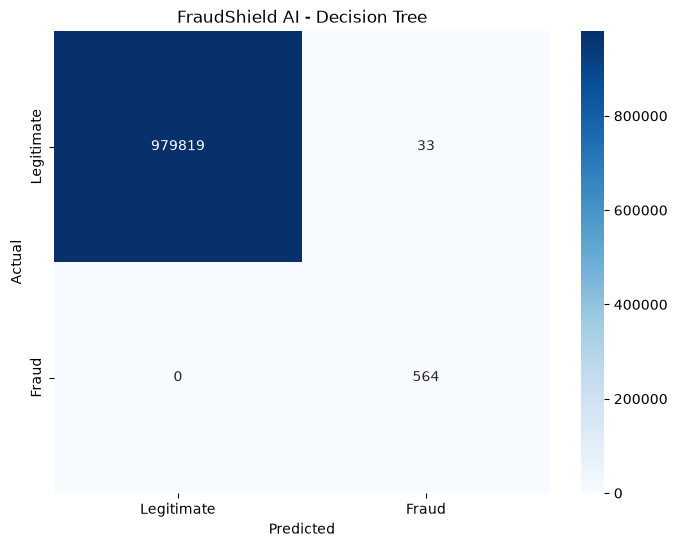

In [8]:
cm = confusion_matrix(y_val, dt_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("FraudShield AI - Decision Tree")

plt.show()

In [9]:
joblib.dump(
    dt_model,
    "../models/decision_tree.pkl"
)

print("Decision Tree saved successfully!")

Decision Tree saved successfully!
